# Análisis de causas

Celda 1: carga

In [1]:
from pathlib import Path
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

BASE        = Path(r"C:\Users\fsociety\Videos\Proyecto_EEVV")
PROCESADO   = BASE / "datos" / "procesado"
ORO         = BASE / "datos" / "oro"
DICCIONARIO = BASE / "documentacion" / "diccionario_variables_eevv.xlsx"
pd.set_option("display.max_colwidth", 80)

defun = pd.read_parquet(PROCESADO / "defunciones_primera_infancia_pacifico.parquet")
defun["grupo_edad_analisis"] = defun["grupo_edad_analisis"].cat.reorder_categories(
    ["Neonatal", "Posneonatal", "1 a 4 años"], ordered=True)

catalogo = pd.read_excel(DICCIONARIO, sheet_name="causas_lista_667", dtype=str)
catalogo = catalogo[catalogo["codigo"].str.fullmatch(r"\d{3}", na=False)]
print("Defunciones:", defun.shape, "| Causas en el catálogo:", len(catalogo))

Defunciones: (3217, 67) | Causas en el catálogo: 68


Celda 2: agregar los nombres de las causas

In [2]:
n_antes = len(defun)
defun = (defun.merge(catalogo[["codigo", "causa", "gran_grupo"]], how="left",
                     left_on="causa_lista_667", right_on="codigo")
              .drop(columns="codigo"))

assert len(defun) == n_antes, "El cruce cambió el número de filas"
assert defun["causa"].notna().all(), "Hay códigos de causa sin nombre en el catálogo"

TOP10 = defun["causa"].value_counts().head(10).index.tolist()
defun["causa_grupo"] = defun["causa"].where(defun["causa"].isin(TOP10), "Otras causas")
defun["causa_grupo"].value_counts()

causa_grupo
Malformaciones congénitas, deformidades y anomalías cromosómicas                              652
Otras causas                                                                                  647
Trastornos respiratorios específicos del período perinatal                                    474
Resto de ciertas afecciones originadas en el período perinatal                                320
Infecciones respiratorias agudas                                                              209
Deficiencias nutricionales y anemias nutricionales                                            205
Sepsis bacteriana del recién nacido                                                           203
Feto y recién nacido afectados por complicaciones obstétricas y traumatismo del nacimiento    190
Enfermedades infecciosas intestinales                                                         121
Feto y recién nacido afectados por ciertas afecciones maternas                                112
Enfermed

Celda 3: las 5 causas principales por grupo de edad

In [3]:
def ranking(df, por, n=5):
    t = df.groupby([por, "causa"], observed=True).size().rename("defunciones").reset_index()
    t["%"] = (t["defunciones"] / t.groupby(por, observed=True)["defunciones"].transform("sum") * 100).round(1)
    t["puesto"] = t.groupby(por, observed=True)["defunciones"].rank(method="first", ascending=False).astype(int)
    return t[t["puesto"] <= n].sort_values([por, "puesto"])

ranking(defun, "grupo_edad_analisis")

,grupo_edad_analisis,causa,defunciones,%,puesto
17,Neonatal,Trastornos respiratorios específicos del período perinatal,375,24.6,1
9,Neonatal,"Malformaciones congénitas, deformidades y anomalías cromosómicas",331,21.7,2
11,Neonatal,Resto de ciertas afecciones originadas en el período perinatal,257,16.9,3
6,Neonatal,Feto y recién nacido afectados por complicaciones obstétricas y traumatismo ...,184,12.1,4
15,Neonatal,Sepsis bacteriana del recién nacido,181,11.9,5
43,Posneonatal,"Malformaciones congénitas, deformidades y anomalías cromosómicas",245,24.0,1
39,Posneonatal,Infecciones respiratorias agudas,138,13.5,2
26,Posneonatal,Deficiencias nutricionales y anemias nutricionales,116,11.4,3
55,Posneonatal,Trastornos respiratorios específicos del período perinatal,92,9.0,4
33,Posneonatal,Enfermedades infecciosas intestinales,67,6.6,5


Celdas 4 y 5: composición por departamento y su gráfico

In [4]:
comp = pd.crosstab(defun["causa_grupo"], defun["dpto_residencia_nombre"],
                   normalize="columns").mul(100).round(1)
comp = comp.loc[TOP10 + ["Otras causas"]]
comp

dpto_residencia_nombre,Cauca,Chocó,Nariño,Valle del Cauca
causa_grupo,,,,
"Malformaciones congénitas, deformidades y anomalías cromosómicas",19.5,11.2,24.2,24.5
Trastornos respiratorios específicos del período perinatal,16.4,11.5,16.7,15.1
Resto de ciertas afecciones originadas en el período perinatal,12.7,6.6,7.7,11.6
Infecciones respiratorias agudas,5.1,9.8,4.2,6.0
Deficiencias nutricionales y anemias nutricionales,2.1,18.0,2.9,2.7
Sepsis bacteriana del recién nacido,8.9,6.3,5.2,5.6
Feto y recién nacido afectados por complicaciones obstétricas y traumatismo del nacimiento,6.3,1.4,5.4,8.6
Enfermedades infecciosas intestinales,2.1,10.1,1.3,1.7
Feto y recién nacido afectados por ciertas afecciones maternas,3.1,0.8,3.1,5.4


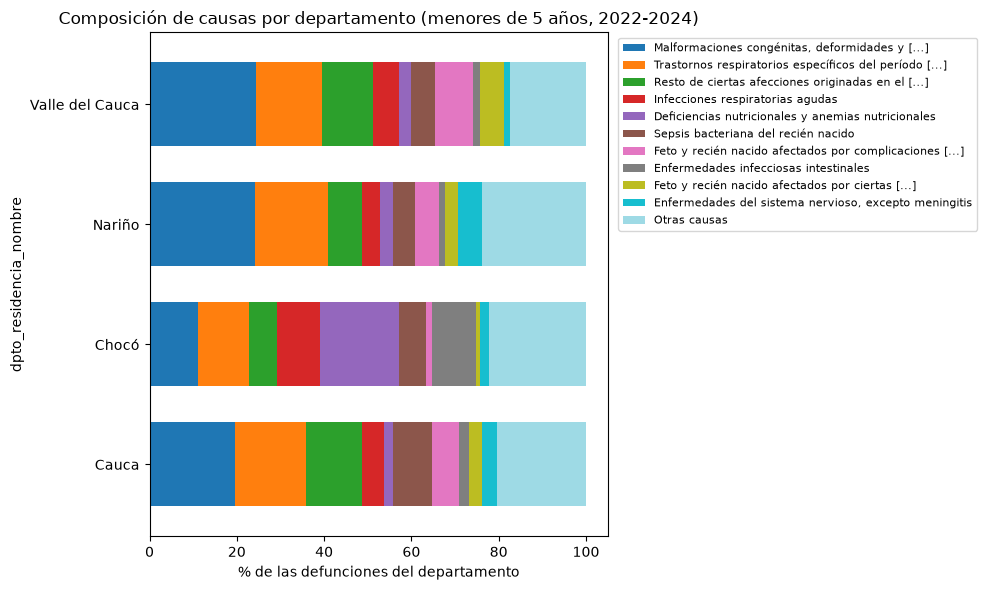

In [5]:
fig, ax = plt.subplots(figsize=(10, 6))
comp.T.plot(kind="barh", stacked=True, ax=ax, colormap="tab20", width=0.7)
ax.set_xlabel("% de las defunciones del departamento")
ax.legend([textwrap.shorten(c, 55) for c in comp.index],
          bbox_to_anchor=(1.01, 1), loc="upper left", fontsize=8)
ax.set_title("Composición de causas por departamento (menores de 5 años, 2022-2024)")
plt.tight_layout()
plt.show()

Celda 6: cambios entre 2022 y 2024

In [6]:
t = pd.crosstab(defun["causa_grupo"], defun["anio"])
N = t.sum()
p22, p24 = t[2022] / N[2022], t[2024] / N[2024]
dif = (p24 - p22) * 100
ee  = np.sqrt(p22 * (1 - p22) / N[2022] + p24 * (1 - p24) / N[2024]) * 100

cambios = pd.DataFrame({"% 2022": p22 * 100, "% 2024": p24 * 100, "diferencia_pp": dif,
                        "ic_inf": dif - 1.96 * ee, "ic_sup": dif + 1.96 * ee}).round(1)
cambios["concluyente"] = np.where((cambios["ic_inf"] > 0) | (cambios["ic_sup"] < 0), "Sí", "No")
cambios.sort_values("diferencia_pp")

,% 2022,% 2024,diferencia_pp,ic_inf,ic_sup,concluyente
causa_grupo,,,,,,
Otras causas,22.2,18.4,-3.7,-7.1,-0.3,Sí
"Malformaciones congénitas, deformidades y anomalías cromosómicas",21.1,19.0,-2.2,-5.6,1.2,No
Sepsis bacteriana del recién nacido,6.8,5.8,-1.0,-3.1,1.1,No
"Enfermedades del sistema nervioso, excepto meningitis",2.4,2.1,-0.3,-1.6,0.9,No
Deficiencias nutricionales y anemias nutricionales,6.4,6.4,-0.1,-2.1,2.0,No
Trastornos respiratorios específicos del período perinatal,14.5,14.7,0.2,-2.8,3.2,No
Resto de ciertas afecciones originadas en el período perinatal,10.0,10.4,0.4,-2.2,3.0,No
Infecciones respiratorias agudas,5.6,6.5,0.8,-1.2,2.9,No
Feto y recién nacido afectados por ciertas afecciones maternas,3.4,4.4,1.0,-0.7,2.6,No


Celda 7: desnutrición, diarrea y causas externas

In [7]:
desnut = defun[defun["causa_lista_667"] == "602"]
print("Deficiencias nutricionales por departamento y edad:")
print(pd.crosstab(desnut["dpto_residencia_nombre"], desnut["grupo_edad_analisis"],
                  margins=True, margins_name="Total").to_string(), "\n")

eda = defun[defun["causa_lista_667"] == "101"]
print("Enfermedades infecciosas intestinales por departamento y año:")
print(pd.crosstab(eda["dpto_residencia_nombre"], eda["anio"],
                  margins=True, margins_name="Total").to_string(), "\n")

ext = defun[defun["gran_grupo"] == "Causas externas"]
print("Causas externas por grupo de edad:")
print(pd.crosstab(ext["causa"], ext["grupo_edad_analisis"],
                  margins=True, margins_name="Total").to_string())

Deficiencias nutricionales por departamento y edad:
grupo_edad_analisis     Neonatal  Posneonatal  1 a 4 años  Total
dpto_residencia_nombre                                          
Cauca                          2            6           4     12
Chocó                          1           76          65    142
Nariño                         1            8           6     15
Valle del Cauca                0           26          10     36
Total                          4          116          85    205 

Enfermedades infecciosas intestinales por departamento y año:
anio                    2022  2023  2024  Total
dpto_residencia_nombre                         
Cauca                      3     7     2     12
Chocó                     10    33    37     80
Nariño                     2     3     2      7
Valle del Cauca            9     6     7     22
Total                     24    49    48    121 

Causas externas por grupo de edad:
grupo_edad_analisis                                     

Celda 8: calidad de la causa por departamento y año

In [8]:
pd.crosstab(defun["dpto_residencia_nombre"], defun["anio"],
            values=defun["causa_lista_667"].eq("000"), aggfunc="mean").mul(100).round(1)

anio,2022,2023,2024
dpto_residencia_nombre,,,
Cauca,1.3,2.8,3.5
Chocó,1.1,1.9,2.0
Nariño,4.7,1.2,0.6
Valle del Cauca,0.4,0.7,0.2


Celda 9: guardar en la capa oro

In [9]:
causas_conteos = (defun.groupby(["anio", "dpto_residencia_nombre", "grupo_edad_analisis",
                                 "causa_lista_667", "causa", "gran_grupo"], observed=True)
                  .size().rename("defunciones").reset_index())
assert causas_conteos["defunciones"].sum() == len(defun)

causas_conteos.to_parquet(ORO / "causas_conteos.parquet", index=False)
cambios.reset_index().to_parquet(ORO / "causas_cambios_2022_2024.parquet", index=False)
print("Guardado:", causas_conteos.shape)

Guardado: (586, 7)


Celda 10: generar la tabla por sexo

In [10]:
SEXO = {"1": "Masculino", "2": "Femenino", "3": "Indeterminado"}

por_sexo = (defun.assign(sexo=defun["sexo"].astype(str).map(SEXO))
            .groupby(["anio", "dpto_residencia_nombre", "grupo_edad_analisis", "sexo"], observed=True)
            .size().rename("defunciones").reset_index())

assert por_sexo["defunciones"].sum() == len(defun)
por_sexo.to_parquet(ORO / "defunciones_por_sexo.parquet", index=False)
print("Guardado:", por_sexo.shape)

Guardado: (73, 5)
